# Predicting Tokyo Electricity Demand with Machine Learning

**Problem:** predict the electricity demand of the Tokyo (TEPCO) area for each hour, using only information that is known in advance: the **weather forecast** and the **calendar**. Grid operators need this to plan how many power plants to run.

* **Type:** supervised regression. The target is `demand_gw`, the hourly demand in gigawatts.
* **Data:** 39,744 hourly records from 1 Apr 2022 to 12 Oct 2026 (JST). Demand comes from TEPCO Power Grid "でんき予報"; weather comes from the Japan Meteorological Agency.
* **Models:** a seasonal-average baseline, Linear Regression, Random Forest and Gradient Boosting (scikit-learn).

All the code is in `model.py`; this notebook runs it step by step.

In [1]:
import pandas as pd, numpy as np
from IPython.display import Image, display
pd.set_option("display.width", 200)
import model as Mdl

## 1. Prepare the dataset

In [2]:
raw = Mdl.load()
print(raw.shape)
raw[["demand_gw", "temp_tokyo_c", "temp_kanto_c", "rh_tokyo_pct", "sun_kanto_h", "hour", "is_workday"]].describe().round(2)

(39744, 17)


,demand_gw,temp_tokyo_c,temp_kanto_c,rh_tokyo_pct,sun_kanto_h,hour
count,39744.00,39744.00,39744.00,39744.00,39744.00,39744.00
mean,31.71,17.96,17.81,69.63,0.25,11.50
std,7.07,8.44,8.53,19.41,0.37,6.92
min,18.53,-3.15,-3.17,16.50,0.00,0.00
25%,26.35,11.05,10.86,55.50,0.00,5.75
50%,30.71,18.40,18.32,71.00,0.00,11.50
75%,35.89,24.95,24.95,85.00,0.49,17.25
max,59.30,38.05,36.73,100.00,1.00,23.00


In [3]:
print("Missing values per column (raw):")
print(raw.isna().sum()[raw.isna().sum() > 0])
df = Mdl.add_features(raw)
print("\nMissing values in the model features after preparation:", int(df[Mdl.FEATURES].isna().sum().sum()))

Missing values per column (raw):
Series([], dtype: int64)

Missing values in the model features after preparation: 0


## 2. Select relevant features

Only inputs that would be **known before the hour happens** are used. Using anything else would let the model "cheat" (data leakage).

| Group | Features | Why |
|---|---|---|
| Temperature | Tokyo and Kanto (population-weighted) temperature, the last-24 h average, today's maximum | Heating and air-conditioning load |
| Heating / cooling degrees | °C above 22, °C below 16 | Captures the U-shaped temperature effect |
| Other weather | Humidity, sunshine | Hot, humid days need more cooling |
| Time | Hour, month, day of week, plus sine/cosine versions | Daily and yearly cycles |
| Calendar | Workday, public holiday | Offices and factories close |

**Left out on purpose:** past demand, solar output and TEPCO's own forecast. Past demand would make the task much easier, but we want to measure how far weather and the calendar alone can go.

In [4]:
corr = df[["demand_gw", "temp_kanto_c", "cooling_degrees", "heating_degrees", "rh_tokyo_pct", "is_workday", "hour"]].corr()["demand_gw"].drop("demand_gw")
print("Correlation with demand:")
print(corr.round(2).sort_values(ascending=False))
print("\nFeatures used:", Mdl.FEATURES)

Correlation with demand:
cooling_degrees    0.59
hour               0.38
is_workday         0.27
temp_kanto_c       0.21
heating_degrees    0.13
rh_tokyo_pct      -0.28
Name: demand_gw, dtype: float64

Features used: ['temp_tokyo_c', 'temp_kanto_c', 'temp_kanto_24h_mean_c', 'temp_kanto_max_today_c', 'cooling_degrees', 'heating_degrees', 'rh_tokyo_pct', 'sun_kanto_h', 'hour_sin', 'hour_cos', 'doy_sin', 'doy_cos', 'hour', 'dayofweek', 'month', 'is_workday', 'is_holiday']


Temperature on its own correlates only weakly with demand, because the relationship is U-shaped. The **cooling-degree** and **heating-degree** features turn each side of the U into a straight line. That is why they help the linear model so much.

## 3. Split the data into training and testing sets
This is time-series data, so the split is **by date**, not random. The model learns from the past and is tested on a later period it has never seen.

In [5]:
X_train, X_test, y_train, y_test, train, test = Mdl.split(df)
print(f"Training: {X_train.index.min():%Y-%m-%d} to {X_train.index.max():%Y-%m-%d}  ({len(X_train):,} hours, {len(X_train)/len(df):.0%})")
print(f"Testing:  {X_test.index.min():%Y-%m-%d} to {X_test.index.max():%Y-%m-%d}  ({len(X_test):,} hours, {len(X_test)/len(df):.0%})")

Training: 2022-04-01 to 2025-12-31  (32,904 hours, 83%)
Testing:  2026-01-01 to 2026-10-12  (6,840 hours, 17%)


## 4. Train the models and 5. Generate predictions

In [6]:
r = Mdl.run(save=True)          # trains all 4 models, predicts the test set, saves charts, predictions and the best model
r["comparison"]

,MAE_GW,RMSE_GW,MAPE_pct,R2
Baseline (seasonal average),2.847,3.822,9.203,0.689
Linear Regression,1.763,2.238,5.899,0.893
Random Forest,0.904,1.250,2.892,0.967
Gradient Boosting,0.814,1.088,2.589,0.975
TEPCO official forecast (reference),0.352,0.522,1.123,0.994


**Reading the results** (test period Jan–Oct 2026):
* **Gradient Boosting is the best model:** on average it is off by 0.81 GW (**2.6 %**) and explains **97.5 %** of the variation in demand (R² 0.975).
* Random Forest is close behind at 2.9 %. Linear Regression reaches 5.9 %, and the simple seasonal-average baseline 9.2 %.
* TEPCO's own published forecast (1.1 %) is shown only as a reference. It also uses the latest actual demand and its operators' knowledge, which this model deliberately does not.

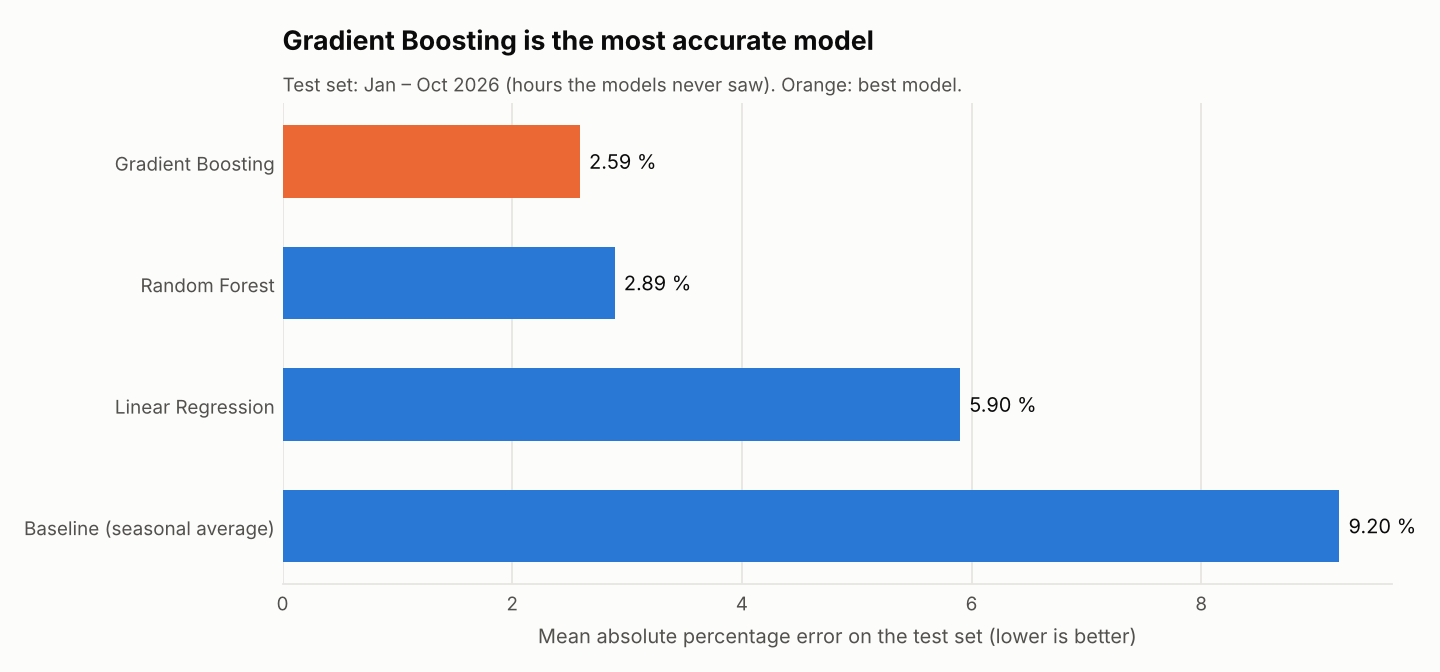

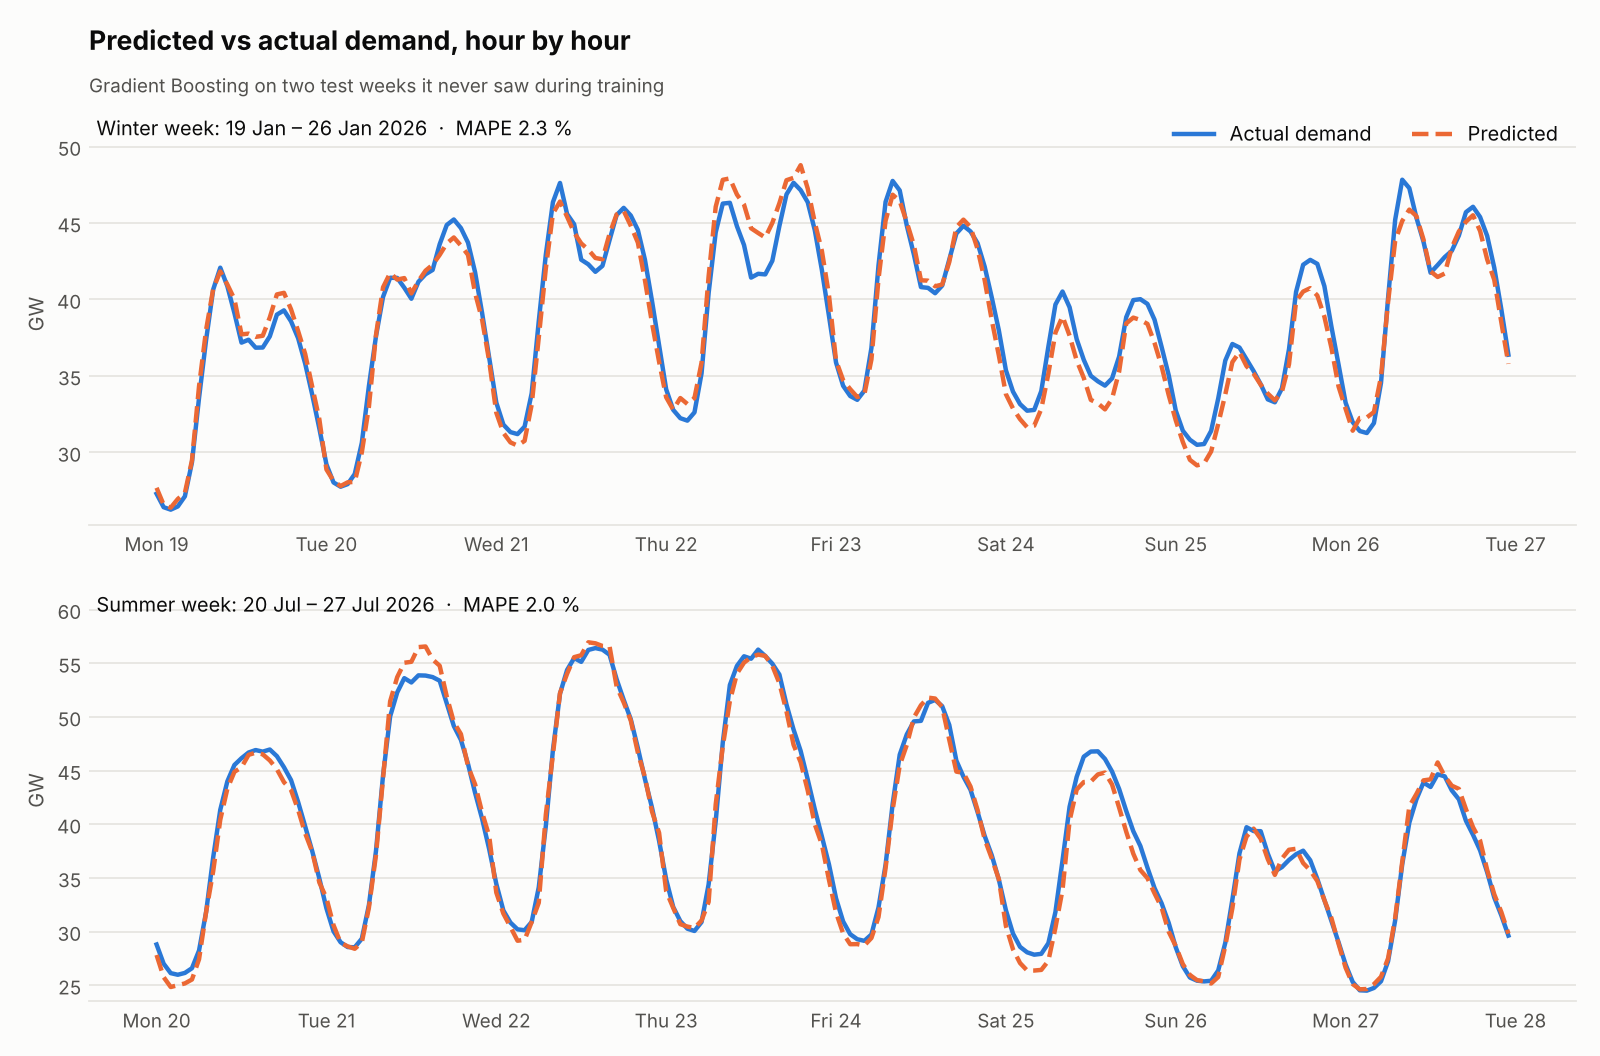

In [7]:
display(Image("fig1_model_comparison.png", width=760))
display(Image("fig2_actual_vs_predicted_weeks.png", width=860))

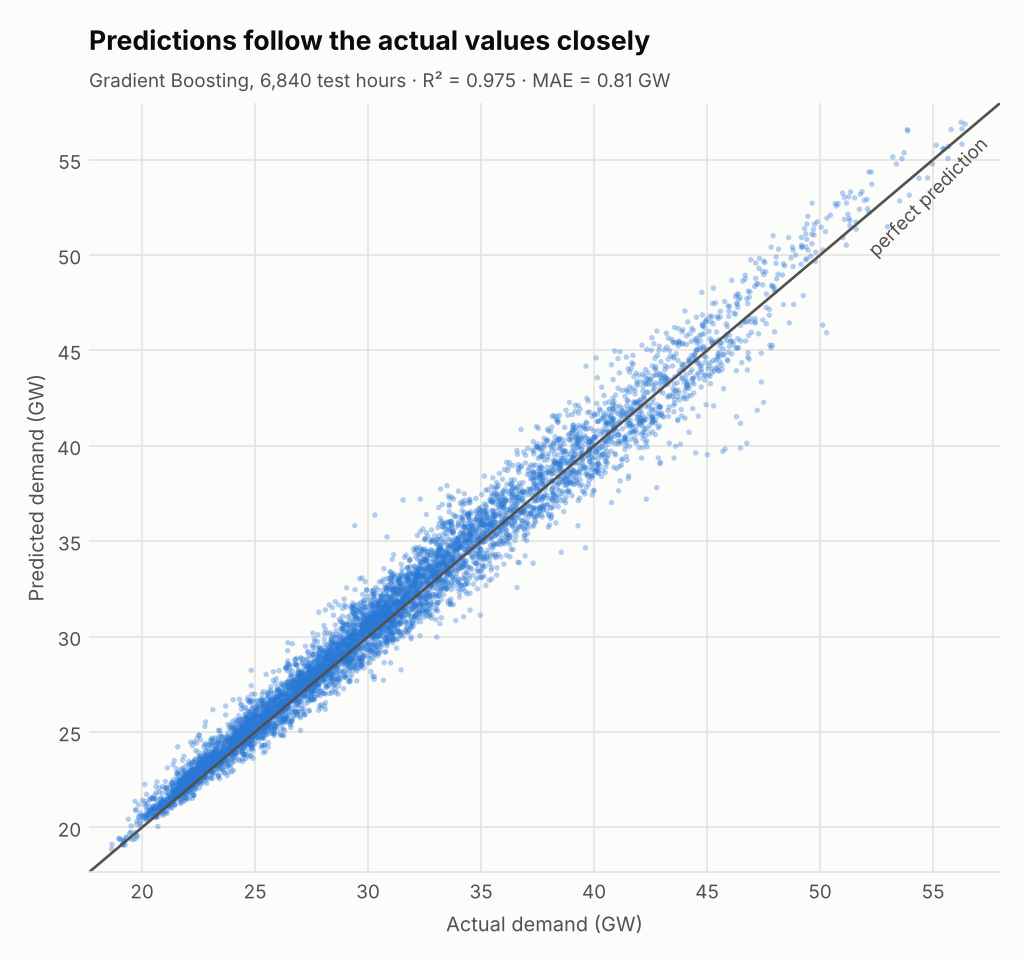

,datetime,actual_gw,predicted_gw,error_gw,tepco_forecast_gw,temp_tokyo_c
0,2026-01-01 00:00:00,26.67,25.72,-0.95,26.87,6.20
1,2026-01-01 01:00:00,25.45,23.98,-1.47,25.48,5.50
2,2026-01-01 02:00:00,24.90,23.62,-1.28,24.96,4.90
3,2026-01-01 03:00:00,24.57,23.60,-0.97,24.68,4.75
4,2026-01-01 04:00:00,24.45,23.46,-0.99,24.63,4.65
5,2026-01-01 05:00:00,24.79,23.77,-1.02,25.03,4.70
6,2026-01-01 06:00:00,25.95,25.73,-0.22,26.00,4.35
7,2026-01-01 07:00:00,27.54,27.70,0.16,27.68,4.05
8,2026-01-01 08:00:00,28.32,28.88,0.56,28.85,4.85
9,2026-01-01 09:00:00,27.23,29.50,2.27,27.65,6.35


In [8]:
display(Image("fig3_predicted_vs_actual_scatter.png", width=560))
pred = pd.read_csv("test_predictions.csv", parse_dates=["datetime"])
pred.head(10)

## 6. Which features matter most?

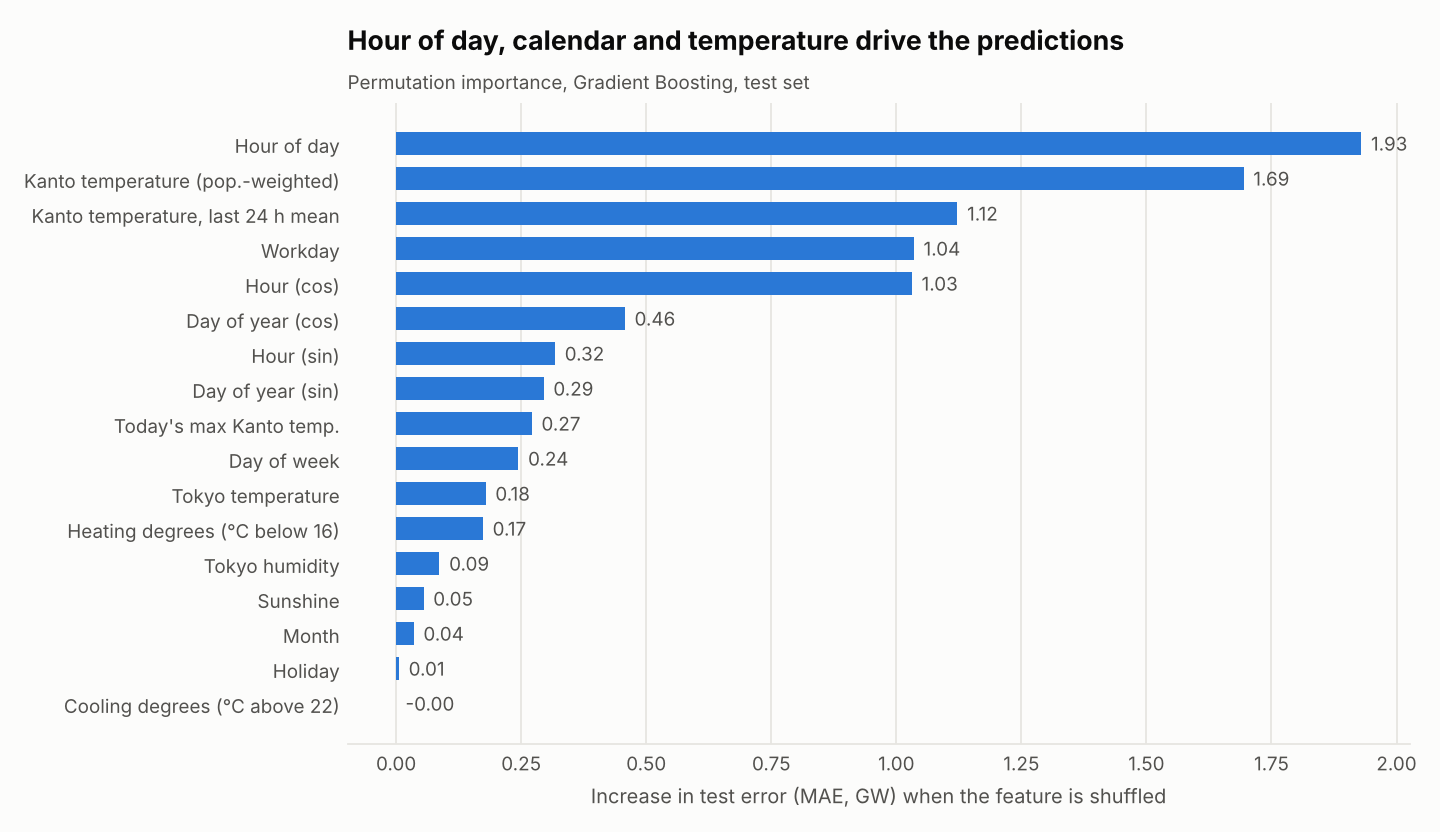

hour                     1.930
temp_kanto_c             1.694
temp_kanto_24h_mean_c    1.122
is_workday               1.035
hour_cos                 1.031
doy_cos                  0.457
hour_sin                 0.318
doy_sin                  0.295
dtype: float64

In [9]:
display(Image("fig4_feature_importance.png", width=760))
r["importance"].round(3).head(8)

The hour of day, the temperature (current and the last 24 hours) and the workday flag are the most important features. Cooling degrees show zero importance in the tree model only because the trees can already learn the same thing from the raw temperature. They mattered for Linear Regression.

## 7. Where does the model make mistakes?

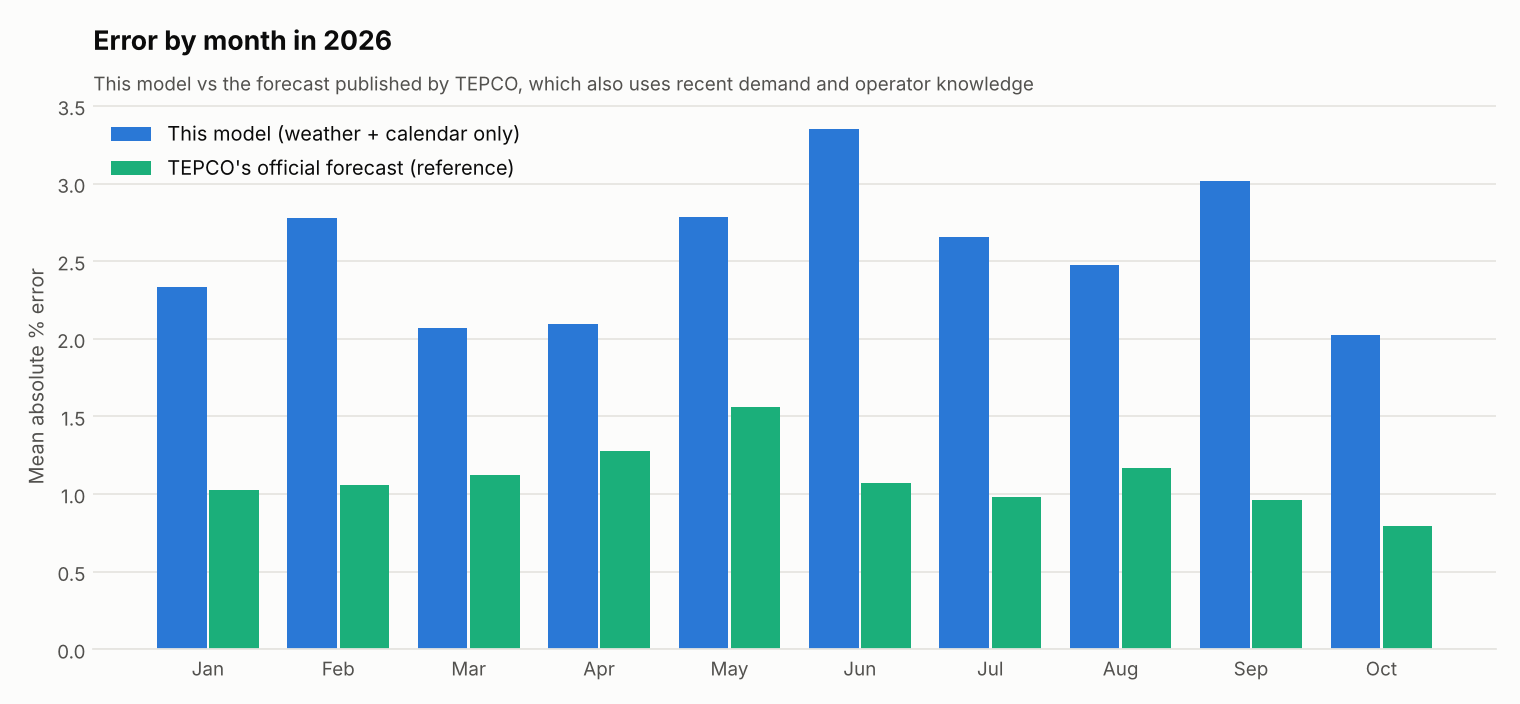

Largest errors in the test set:


,datetime,actual_gw,predicted_gw,temp_tokyo_c
922,2026-02-08 10:00:00,46.76,40.13,-1.15
923,2026-02-08 11:00:00,46.48,39.88,-0.60
5361,2026-08-12 09:00:00,29.41,35.82,24.20
5362,2026-08-12 10:00:00,30.30,36.37,25.45
924,2026-02-08 12:00:00,45.70,39.71,-0.25


In [10]:
display(Image("fig5_error_by_month.png", width=800))
err = pred.assign(abs_err=(pred["predicted_gw"] - pred["actual_gw"]).abs())
print("Largest errors in the test set:")
err.nlargest(5, "abs_err")[["datetime", "actual_gw", "predicted_gw", "temp_tokyo_c"]]

## 8. Use the model for new predictions

In [11]:
import predict
predict.show("2026-08-10", 35.0, 27.0, True)    # hot summer workday
predict.show("2026-04-19", 21.0, 12.0, False)   # mild spring Sunday
_ = predict.show("2027-01-20", 8.0, 1.0, True)  # cold winter workday


2026-08-10 (workday), forecast 27.0–35.0 °C
Predicted peak: 54.7 GW at 13:00 | lowest: 25.7 GW | daily energy: 1012 GWh
                     00:00  01:00  02:00  03:00  04:00  05:00  06:00  07:00  08:00  09:00  10:00  11:00  12:00  13:00  14:00  15:00  16:00  17:00  18:00  19:00  20:00  21:00  22:00  23:00
temp_c                27.5   27.1   27.0   27.1   27.5   28.2   29.0   30.0   31.0   32.0   33.0   33.8   34.5   34.9   35.0   34.9   34.5   33.8   33.0   32.0   31.0   30.0   29.0   28.2
predicted_demand_gw   29.3   26.9   25.7   26.1   27.2   28.2   30.8   36.3   43.2   49.7   51.8   53.0   53.1   54.7   54.6   54.7   53.8   52.0   51.0   49.4   45.6   41.8   38.8   34.4

2026-04-19 (weekend/holiday), forecast 12.0–21.0 °C
Predicted peak: 27.5 GW at 18:00 | lowest: 21.1 GW | daily energy: 574 GWh
                     00:00  01:00  02:00  03:00  04:00  05:00  06:00  07:00  08:00  09:00  10:00  11:00  12:00  13:00  14:00  15:00  16:00  17:00  18:00  19:00  20:00  21:00  22:00  23:00

## Conclusion
* With **weather and calendar features only**, Gradient Boosting predicts hourly Tokyo demand with an average error of **2.6 %** (R² 0.975) on ten months of unseen data. That is 3.5 times better than the seasonal-average baseline.
* Engineering the **heating- and cooling-degree** features improved Linear Regression from 11.0 % to 5.9 % error, because they capture the U-shaped temperature effect.
* The biggest errors happen around **holidays and sudden weather changes**. Adding the previous day's demand would be the next step to get closer to TEPCO's 1.1 %.